# 🔢 50 Pandas + NumPy Integration Practice Questions
> **Instructions:** Each question requires both **Pandas** and **NumPy**. Focus on interoperability, vectorized operations, and building ML-ready datasets.  
> **Do NOT look at solutions** — hints are provided to guide your thinking.  
> Recommended pace: 5–10 questions per day

---

## 🔹 NP1–NP10: Array Conversions & Basic Integration

---

### NP1. Create a NumPy array and convert it to a Pandas Series.
> 💡 **Hint:** `np.array([...])` creates the array. Pass it directly to `pd.Series(array, index=[...], name="...")`.

---

In [152]:
import numpy as np
import pandas as pd

arr = np.array([1,2,3,4,5,6,7,8,9,10])
arr
index1=np.array(['E1','E2','E3','E4','E5','E6','E7','E8','E9','E10'])
series= pd.Series(arr,index=index1,name='serial number')
series

E1      1
E2      2
E3      3
E4      4
E5      5
E6      6
E7      7
E8      8
E9      9
E10    10
Name: serial number, dtype: int64

### NP2. Convert a 2D NumPy array to a Pandas DataFrame.
> 💡 **Hint:** `pd.DataFrame(np_2d_array, columns=[...])` — shape `(n, m)` gives `n` rows and `m` columns.

---

In [153]:
np.random.seed(42)
arr1 = np.random.randint(100,500,20)
arr1 = arr1.reshape(10,2)
arr1

data= pd.DataFrame(arr1)
data.shape

(10, 2)

### NP3. Generate a random dataset using NumPy and store it in a DataFrame.
> 💡 **Hint:** Use `np.random.seed()` for reproducibility. Try `np.random.randn(n, m)` for normal distribution or `np.random.randint(lo, hi, n)` for integers.

---

In [154]:
np.random.seed(42)
arr = np.random.randint(300,500,40)
arr = arr.reshape(10,4)

data1 = pd.DataFrame(arr)
data1

,0,1,2,3
0,402,479,392,314
1,406,371,488,320
2,402,421,374,387
3,416,399,403,451
4,430,449,352,301
5,387,457,337,429
6,491,487,320,460
7,357,321,388,348
8,358,469,487,314
9,489,489,474,489


### NP4. Perform element-wise operations using NumPy and Pandas.
> 💡 **Hint:** You can apply NumPy ufuncs directly on a Pandas Series: `np.sqrt(df["col"])`. The result is a Series.

---

In [155]:
np.sqrt(data1[2])

0    19.798990
1    22.090722
2    19.339080
3    20.074860
4    18.761663
5    18.357560
6    17.888544
7    19.697716
8    22.068076
9    21.771541
Name: 2, dtype: float64

### NP5. Apply `np.mean` on DataFrame columns.
> 💡 **Hint:** `np.mean(df["col"])` works the same as `df["col"].mean()`. Apply to the `.values` array for pure NumPy speed: `np.mean(df["col"].values)`.

---

In [156]:
print(data1[3].mean())

381.3


In [157]:
print(np.mean(data1[3].values))

381.3


### NP6. Replace values using `np.where`.
> 💡 **Hint:** `np.where(condition, value_if_true, value_if_false)` — assign the result back to a column: `df["col"] = np.where(df["col"] > 50, "High", "Low")`.

---

In [158]:
np.where(data[data1[2]<400],200,600)

array([[200, 200],
       [200, 200],
       [200, 200],
       [200, 200],
       [200, 200],
       [200, 200]])

### NP7. Apply logarithmic transformation using `np.log`.
> 💡 **Hint:** `df["col_log"] = np.log(df["col"])`. Note: `np.log(0)` returns `-inf`. Use `np.log1p(x)` which computes `log(1 + x)` to safely handle zeros.

---

In [159]:
data1['np_log 3']=np.log(data1[3])
# data1.drop(columns='np_log',inplace=True) #dropped extra column
data1

,0,1,2,3,np_log 3
0,402,479,392,314,5.749393
1,406,371,488,320,5.768321
2,402,421,374,387,5.958425
3,416,399,403,451,6.111467
4,430,449,352,301,5.707110
5,387,457,337,429,6.061457
6,491,487,320,460,6.131226
7,357,321,388,348,5.852202
8,358,469,487,314,5.749393
9,489,489,474,489,6.192362


### NP8. Apply square root transformation using `np.sqrt`.
> 💡 **Hint:** `df["col_sqrt"] = np.sqrt(df["col"])`. Values must be non-negative; use `np.clip(df["col"], 0, None)` first if negatives are possible.

---

In [160]:
data1['col_sqrt']=np.sqrt(data1[2])
data1.loc[2,2]=np.nan
data1.loc[4,2]=np.nan
data1.loc[6,2]=np.nan
data1['sqrt1'] = np.sqrt(data1[1])
data1


,0,1,2,3,np_log 3,col_sqrt,sqrt1
0,402,479,392.0,314,5.749393,19.798990,21.886069
1,406,371,488.0,320,5.768321,22.090722,19.261360
2,402,421,NaN,387,5.958425,19.339080,20.518285
3,416,399,403.0,451,6.111467,20.074860,19.974984
4,430,449,NaN,301,5.707110,18.761663,21.189620
5,387,457,337.0,429,6.061457,18.357560,21.377558
6,491,487,NaN,460,6.131226,17.888544,22.068076
7,357,321,388.0,348,5.852202,19.697716,17.916473
8,358,469,487.0,314,5.749393,22.068076,21.656408
9,489,489,474.0,489,6.192362,21.771541,22.113344


### NP9. Use NumPy functions inside `apply()`.
> 💡 **Hint:** `df["col"].apply(lambda x: np.log(x))` — or pass the NumPy function directly: `df["col"].apply(np.log)`.

---

In [161]:
data1['log_3'] = data1[3].apply(lambda x:np.log(x))
data1

,0,1,2,3,np_log 3,col_sqrt,sqrt1,log_3
0,402,479,392.0,314,5.749393,19.798990,21.886069,5.749393
1,406,371,488.0,320,5.768321,22.090722,19.261360,5.768321
2,402,421,NaN,387,5.958425,19.339080,20.518285,5.958425
3,416,399,403.0,451,6.111467,20.074860,19.974984,6.111467
4,430,449,NaN,301,5.707110,18.761663,21.189620,5.707110
5,387,457,337.0,429,6.061457,18.357560,21.377558,6.061457
6,491,487,NaN,460,6.131226,17.888544,22.068076,6.131226
7,357,321,388.0,348,5.852202,19.697716,17.916473,5.852202
8,358,469,487.0,314,5.749393,22.068076,21.656408,5.749393
9,489,489,474.0,489,6.192362,21.771541,22.113344,6.192362


### NP10. Perform broadcasting in a DataFrame using NumPy.
> 💡 **Hint:** Extract `.values` (a 2D NumPy array) and multiply by a weights array: `df[cols].values @ weights_array`. The result can be assigned back as a new column.

In [162]:
# data.drop(columns=['matrix_mul'],inplace=True)
data

,0,1
0,202,448
1,370,206
2,171,288
3,120,202
4,221,314
5,430,187
6,472,199
7,459,251
8,230,249
9,408,357


In [163]:
weight_arr= np.arange(11,21).reshape(1,10)
data1['matrix_mul'] = data1[3] @ weight_arr.ravel()
data1

,0,1,2,3,np_log 3,col_sqrt,sqrt1,log_3,matrix_mul
0,402,479,392.0,314,5.749393,19.798990,21.886069,5.749393,59848
1,406,371,488.0,320,5.768321,22.090722,19.261360,5.768321,59848
2,402,421,NaN,387,5.958425,19.339080,20.518285,5.958425,59848
3,416,399,403.0,451,6.111467,20.074860,19.974984,6.111467,59848
4,430,449,NaN,301,5.707110,18.761663,21.189620,5.707110,59848
5,387,457,337.0,429,6.061457,18.357560,21.377558,6.061457,59848
6,491,487,NaN,460,6.131226,17.888544,22.068076,6.131226,59848
7,357,321,388.0,348,5.852202,19.697716,17.916473,5.852202,59848
8,358,469,487.0,314,5.749393,22.068076,21.656408,5.749393,59848
9,489,489,474.0,489,6.192362,21.771541,22.113344,6.192362,59848


## 🔹 NP11–NP20: Data Filtering, Transformation & Statistics

---

In [164]:
import pandas as pd
import numpy as np

data = {
    'Emp_ID': ['E101','E102','E103','E104','E105',
               'E106','E107','E108','E109','E110',
               'E111','E112','E113','E114','E115'],

    'Name': ['Bapu','Parag','Rohit','Sachin','Dipak',
             'Virat','Neha','Priya','Ajay','Sneha',
             'Ravi','Meena','Pooja','Ankit','Kiran'],

    'Department': ['IT','HR','Finance','IT','Sales',
                   'Finance','HR','IT','Sales','HR',
                   'Finance','IT','Sales','HR','IT'],

    'Age': [25,31,28,35,29,
            40,27,34,30,26,
            38,32,29,36,41],

    'Experience': [2,6,4,10,5,
                   14,3,8,6,2,
                   12,7,5,9,15],

    'Salary': [50000,45000,60000,np.nan,55000,
               95000,48000,70000,62000,47000,
               90000,68000,np.nan,72000,100000],

    'Performance': ['Good','Excellent','Average','Good','Excellent',
                    'Excellent','Good','Average','Good','Average',
                    'Excellent','Good','Average','Excellent','Good'],

    'Joining_Date': pd.to_datetime([
        '2022-01-15','2021-06-20','2020-03-10',
        '2018-08-01','2021-11-05',
        '2015-02-14','2023-01-12',
        '2019-09-17','2020-07-19',
        '2023-04-01','2016-05-28',
        '2019-12-10','2022-02-22',
        '2018-11-30','2014-06-18'
    ])
}

df = pd.DataFrame(data)

# Add a duplicate row intentionally
df = pd.concat([df, df.iloc[[5]]], ignore_index=True)

print(df)

   Emp_ID    Name Department  Age  Experience    Salary Performance  \
0    E101    Bapu         IT   25           2   50000.0        Good   
1    E102   Parag         HR   31           6   45000.0   Excellent   
2    E103   Rohit    Finance   28           4   60000.0     Average   
3    E104  Sachin         IT   35          10       NaN        Good   
4    E105   Dipak      Sales   29           5   55000.0   Excellent   
5    E106   Virat    Finance   40          14   95000.0   Excellent   
6    E107    Neha         HR   27           3   48000.0        Good   
7    E108   Priya         IT   34           8   70000.0     Average   
8    E109    Ajay      Sales   30           6   62000.0        Good   
9    E110   Sneha         HR   26           2   47000.0     Average   
10   E111    Ravi    Finance   38          12   90000.0   Excellent   
11   E112   Meena         IT   32           7   68000.0        Good   
12   E113   Pooja      Sales   29           5       NaN     Average   
13   E

### NP11. Filter DataFrame rows using a NumPy boolean mask.
> 💡 **Hint:** `mask = np.array(df["col"]) > threshold` creates a NumPy boolean array. Use `df[mask]` to filter.

---

In [165]:
mask=df['Salary'] > df['Salary'].mean()
df[mask]

,Emp_ID,Name,Department,Age,Experience,Salary,Performance,Joining_Date
5,E106,Virat,Finance,40,14,95000.0,Excellent,2015-02-14
7,E108,Priya,IT,34,8,70000.0,Average,2019-09-17
10,E111,Ravi,Finance,38,12,90000.0,Excellent,2016-05-28
13,E114,Ankit,HR,36,9,72000.0,Excellent,2018-11-30
14,E115,Kiran,IT,41,15,100000.0,Good,2014-06-18
15,E106,Virat,Finance,40,14,95000.0,Excellent,2015-02-14


### NP12. Count non-zero values in a column using NumPy.
> 💡 **Hint:** `np.count_nonzero(df["col"].values)` or `np.count_nonzero(df["col"].values != 0)`.

---

In [166]:
print(np.count_nonzero(df['Salary'].values))
np.count_nonzero(df['Age'].values!=0)

16


np.int64(16)

### NP13. Find unique values using `np.unique`.
> 💡 **Hint:** `np.unique(df["col"])` returns sorted unique values. Use `return_counts=True` to also get the frequency of each unique value.

---

In [167]:
np.unique(df['Salary'],return_counts=True)

(array([ 45000.,  47000.,  48000.,  50000.,  55000.,  60000.,  62000.,
         68000.,  70000.,  72000.,  90000.,  95000., 100000.,     nan]),
 array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2]))

### NP14. Flatten DataFrame values to a 1D NumPy array.
> 💡 **Hint:** `df[["col1","col2"]].values.flatten()` — the `.flatten()` method converts the 2D array to 1D row-by-row.

---

In [168]:
df['Salary'].values.flatten() #Cannot flatten string array

array([ 50000.,  45000.,  60000.,     nan,  55000.,  95000.,  48000.,
        70000.,  62000.,  47000.,  90000.,  68000.,     nan,  72000.,
       100000.,  95000.])

### NP15. Reshape a NumPy array before creating a DataFrame.
> 💡 **Hint:** `np.arange(1, 25).reshape(6, 4)` creates a 6×4 array. Pass directly to `pd.DataFrame(arr, columns=[...])`.

---

In [169]:
arr= np.arange(1,25).reshape(4,6)
arr1=pd.DataFrame(arr,columns=['Name','Rollno','Marks','Fname','Lname','Kname'])
arr1.rename(columns={'Kname':'Final'},inplace=True)
arr1

,Name,Rollno,Marks,Fname,Lname,Final
0,1,2,3,4,5,6
1,7,8,9,10,11,12
2,13,14,15,16,17,18
3,19,20,21,22,23,24


### NP16. Perform matrix multiplication using `np.dot`.
> 💡 **Hint:** `np.dot(A, B)` or `A @ B`. Extract `.values` from DataFrames first, then wrap the result in a new `pd.DataFrame(result, columns=[...])`.

---

In [170]:
#corrected
import seaborn as sns
tips=sns.load_dataset('tips')
A = tips[['total_bill', 'tip']].values      # Shape (244, 2)

B = np.array([[2, 1],
              [3, 4]])                      # Shape (2, 2)

result = np.dot(A, B)

result_df = pd.DataFrame(result,
                         columns=['Col1', 'Col2'])

result_df.head()

,Col1,Col2
0,37.01,21.03
1,25.66,16.98
2,52.52,35.01
3,57.29,36.92
4,60.01,39.03


In [171]:
df['Salary']=df['Salary'].fillna(10)
A=df['Salary']
A=A.to_numpy().reshape(16,1)
B=df['Age']
B=B.to_numpy().reshape(1,16)

result= A @ B
print(result)

[[1.250e+06 1.550e+06 1.400e+06 1.750e+06 1.450e+06 2.000e+06 1.350e+06
  1.700e+06 1.500e+06 1.300e+06 1.900e+06 1.600e+06 1.450e+06 1.800e+06
  2.050e+06 2.000e+06]
 [1.125e+06 1.395e+06 1.260e+06 1.575e+06 1.305e+06 1.800e+06 1.215e+06
  1.530e+06 1.350e+06 1.170e+06 1.710e+06 1.440e+06 1.305e+06 1.620e+06
  1.845e+06 1.800e+06]
 [1.500e+06 1.860e+06 1.680e+06 2.100e+06 1.740e+06 2.400e+06 1.620e+06
  2.040e+06 1.800e+06 1.560e+06 2.280e+06 1.920e+06 1.740e+06 2.160e+06
  2.460e+06 2.400e+06]
 [2.500e+02 3.100e+02 2.800e+02 3.500e+02 2.900e+02 4.000e+02 2.700e+02
  3.400e+02 3.000e+02 2.600e+02 3.800e+02 3.200e+02 2.900e+02 3.600e+02
  4.100e+02 4.000e+02]
 [1.375e+06 1.705e+06 1.540e+06 1.925e+06 1.595e+06 2.200e+06 1.485e+06
  1.870e+06 1.650e+06 1.430e+06 2.090e+06 1.760e+06 1.595e+06 1.980e+06
  2.255e+06 2.200e+06]
 [2.375e+06 2.945e+06 2.660e+06 3.325e+06 2.755e+06 3.800e+06 2.565e+06
  3.230e+06 2.850e+06 2.470e+06 3.610e+06 3.040e+06 2.755e+06 3.420e+06
  3.895e+06 3.800e+06

### NP17. Normalize data using NumPy (Min-Max scaling).
> 💡 **Hint:** `arr = df[cols].values` then `(arr - arr.min(axis=0)) / (arr.max(axis=0) - arr.min(axis=0))`. Use `axis=0` to operate column-wise.

---

In [172]:
arr=df['Salary'].values

norma_lize = (arr-arr.min(axis=0))/(arr.max(axis=0)-arr.min(axis=0))
print(norma_lize)



[0.49994999 0.44994499 0.59996    0.         0.549955   0.949995
 0.47994799 0.69997    0.619962   0.46994699 0.89999    0.679968
 0.         0.719972   1.         0.949995  ]


### NP18. Standardize data using Z-score with NumPy.
> 💡 **Hint:** `z = (arr - arr.mean(axis=0)) / arr.std(axis=0)`. Wrap the result in a DataFrame using the original column names.

---

In [173]:
z=(arr-arr.mean(axis=0))/(arr.std(axis=0))
print(z)

[-0.34268431 -0.51727827  0.00650363 -2.08827478 -0.16809034  1.22866139
 -0.41252189  0.35569156  0.07634121 -0.44744069  1.05406742  0.28585397
 -2.08827478  0.42552914  1.40325536  1.22866139]


### NP19. Clip values using `np.clip`.
> 💡 **Hint:** `np.clip(df["col"].values, a_min=lower_bound, a_max=upper_bound)` — values outside the range are replaced by the boundary values.

---

In [174]:
np.clip(df['Salary'],10000,60000)

0     50000.0
1     45000.0
2     60000.0
3     10000.0
4     55000.0
5     60000.0
6     48000.0
7     60000.0
8     60000.0
9     47000.0
10    60000.0
11    60000.0
12    10000.0
13    60000.0
14    60000.0
15    60000.0
Name: Salary, dtype: float64

### NP20. Handle missing values using NumPy.
> 💡 **Hint:** Detect NaN with `np.isnan(arr)`. Fill using `np.nanmean(arr)` to compute the mean ignoring NaN, then replace: `arr[np.isnan(arr)] = np.nanmean(arr)`.

---

In [175]:
nan=np.isnan(df['Salary'])

In [176]:
df['Salary']=np.where(np.isnan(df['Salary']),np.nanmean(df['Salary']).round(2),df['Salary'])
df

,Emp_ID,Name,Department,Age,Experience,Salary,Performance,Joining_Date
0,E101,Bapu,IT,25,2,50000.0,Good,2022-01-15
1,E102,Parag,HR,31,6,45000.0,Excellent,2021-06-20
2,E103,Rohit,Finance,28,4,60000.0,Average,2020-03-10
3,E104,Sachin,IT,35,10,10.0,Good,2018-08-01
4,E105,Dipak,Sales,29,5,55000.0,Excellent,2021-11-05
5,E106,Virat,Finance,40,14,95000.0,Excellent,2015-02-14
6,E107,Neha,HR,27,3,48000.0,Good,2023-01-12
7,E108,Priya,IT,34,8,70000.0,Average,2019-09-17
8,E109,Ajay,Sales,30,6,62000.0,Good,2020-07-19
9,E110,Sneha,HR,26,2,47000.0,Average,2023-04-01


## 🔹 NP21–NP30: Performance, Sorting & Statistical Analysis

---

In [177]:
import pandas as pd
import numpy as np

data = {
    'Emp_ID': range(101,131),

    'Name': ['Bapu','Parag','Sachin','Dipak','Rohit',
             'Virat','Aman','Neha','Pooja','Karan',
             'Anjali','Sneha','Riya','Ajay','Rahul',
             'Priya','Sagar','Kunal','Meera','Aditi',
             'Arjun','Vikas','Nikita','Tanvi','Sanchita',
             'Mohit','Tejas','Ankit','Yash','Nilesh'],

    'Department': ['IT','HR','Finance','Sales','IT',
                   'HR','Finance','Sales','IT','HR',
                   'Finance','Sales','IT','HR','Finance',
                   'Sales','IT','HR','Finance','Sales',
                   'IT','HR','Finance','Sales','IT',
                   'HR','Finance','Sales','IT','HR'],

    'Salary': [50000,45000,np.nan,62000,55000,
               47000,58000,np.nan,52000,49000,
               61000,53000,54000,np.nan,60000,
               51000,56000,48000,np.nan,59000,
               57000,46000,64000,50000,np.nan,
               65000,52000,61000,55000,58000],

    'Age': [25,28,30,27,np.nan,
            32,29,31,26,24,
            35,np.nan,27,33,29,
            30,28,34,26,np.nan,
            31,25,36,27,29,
            32,30,np.nan,28,35],

    'Experience': [2,5,7,4,3,
                   np.nan,6,8,2,1,
                   10,5,4,9,np.nan,
                   3,6,7,2,8,
                   5,1,np.nan,4,6,
                   9,3,7,5,10],

    'Performance': ['Good','Excellent','Average','Good',np.nan,
                    'Average','Excellent','Good','Poor','Good',
                    'Excellent','Average','Good',np.nan,'Excellent',
                    'Poor','Good','Average','Good','Excellent',
                    'Average','Poor',np.nan,'Good','Excellent',
                    'Good','Average','Excellent','Poor','Good'],

    'Bonus': [5000,np.nan,3500,6000,4500,
              3000,5500,4000,np.nan,3500,
              7000,4500,5000,3000,np.nan,
              4000,5500,3500,5000,6500,
              6000,2500,np.nan,4500,7000,
              5500,4000,6000,3500,np.nan]
}

df = pd.DataFrame(data)

df

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,NaN
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0
3,104,Dipak,Sales,62000.0,27.0,4.0,Good,6000.0
4,105,Rohit,IT,55000.0,NaN,3.0,NaN,4500.0
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0
6,107,Aman,Finance,58000.0,29.0,6.0,Excellent,5500.0
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,NaN
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0


### NP21. Compare NumPy vs Pandas performance on a large array.
> 💡 **Hint:** Use `time.time()` before and after each operation. Apply the same computation (`arr * 2 + 1`) to a raw NumPy array and a Pandas Series. NumPy is typically faster on pure numeric operations.

---

In [178]:
# numpy time 
import time

start_time= time.time()
arr= np.arange(1000000)
multi = arr * 40 + 1

time_required = time.time()-start_time

print('Time required for numpy operation = ',time_required)

#time required for pandas series
start = time.time()
series = pd.Series(arr)
mul = series * 40 + 1
time1 = time.time() - start

print('Time required for pandas operation = ',time1)

number_of_times_faster = time_required/start
print(number_of_times_faster)


Time required for numpy operation =  0.008375883102416992
Time required for pandas operation =  0.007876873016357422
4.7008191406232535e-12


### NP22. Calculate cumulative sum using NumPy.
> 💡 **Hint:** `np.cumsum(df["col"].values)` — assign back: `df["cum_col"] = np.cumsum(df["col"])`.

---

In [179]:

df['Salary'].fillna(df['Salary'].mean(),inplace=True)
df
df['cumsum_Salary']=np.cumsum(df['Salary'])
df

C:\Users\bapuc\AppData\Local\Temp\ipykernel_25872\2624783738.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Salary'].fillna(df['Salary'].mean(),inplace=True)


,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,NaN,95000.0
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0,NaN
3,104,Dipak,Sales,62000.0,27.0,4.0,Good,6000.0,157000.0
4,105,Rohit,IT,55000.0,NaN,3.0,NaN,4500.0,212000.0
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0
6,107,Aman,Finance,58000.0,29.0,6.0,Excellent,5500.0,317000.0
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0,NaN
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,NaN,369000.0
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0


### NP23. Use `np.argmax` and `np.argmin`.
> 💡 **Hint:** `np.argmax(df["col"].values)` returns the **integer position** of the maximum. Use `df.iloc[idx]` or `df.loc[idx]` to retrieve the full row.

---

In [180]:
idx = np.argmin(df['Salary'])
df.iloc[idx]

Emp_ID                 102
Name                 Parag
Department              HR
Salary             45000.0
Age                   28.0
Experience             5.0
Performance      Excellent
Bonus                  NaN
cumsum_Salary      95000.0
Name: 1, dtype: object

In [181]:
max1 = np.argmax(df['Salary'])
max1
df.loc[max1]

Emp_ID                 126
Name                 Mohit
Department              HR
Salary             65000.0
Age                   32.0
Experience             9.0
Performance           Good
Bonus               5500.0
cumsum_Salary    1142000.0
Name: 25, dtype: object

### NP24. Sort values using NumPy `np.argsort`.
> 💡 **Hint:** `sorted_idx = np.argsort(df["col"].values)` gives indices that would sort the array. Use `df.iloc[sorted_idx]` to reorder the DataFrame.

---

In [182]:
sorted_index =np.argsort(df['Salary'])
df.loc[sorted_index]

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,NaN,95000.0
21,122,Vikas,HR,46000.0,25.0,1.0,Poor,2500.0,963000.0
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0
17,118,Kunal,HR,48000.0,34.0,7.0,Average,3500.0,801000.0
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0
23,124,Tanvi,Sales,50000.0,27.0,4.0,Good,4500.0,1077000.0
15,116,Priya,Sales,51000.0,30.0,3.0,Poor,4000.0,697000.0
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,NaN,369000.0
26,127,Tejas,Finance,52000.0,30.0,3.0,Average,4000.0,1194000.0


In [183]:
sorted_index =np.argsort(df['Salary'])
df.iloc[sorted_index]

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,NaN,95000.0
21,122,Vikas,HR,46000.0,25.0,1.0,Poor,2500.0,963000.0
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0
17,118,Kunal,HR,48000.0,34.0,7.0,Average,3500.0,801000.0
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0
23,124,Tanvi,Sales,50000.0,27.0,4.0,Good,4500.0,1077000.0
15,116,Priya,Sales,51000.0,30.0,3.0,Poor,4000.0,697000.0
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,NaN,369000.0
26,127,Tejas,Finance,52000.0,30.0,3.0,Average,4000.0,1194000.0


### NP25. Compute correlation using `np.corrcoef`.
> 💡 **Hint:** `np.corrcoef([df["col1"].values, df["col2"].values])` returns a 2×2 correlation matrix. Wrap in a DataFrame for readability. Compare with `df.corr()`.

---

In [184]:
df['Bonus']=df['Bonus'].fillna(df['Bonus'].mean())
df

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,4720.0,95000.0
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0,NaN
3,104,Dipak,Sales,62000.0,27.0,4.0,Good,6000.0,157000.0
4,105,Rohit,IT,55000.0,NaN,3.0,NaN,4500.0,212000.0
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0
6,107,Aman,Finance,58000.0,29.0,6.0,Excellent,5500.0,317000.0
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0,NaN
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,4720.0,369000.0
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0


In [185]:
corr1 = np.corrcoef(df['Salary'],df['Bonus'])
corr1

array([[nan, nan],
       [nan,  1.]])

### NP26. Detect NaN values using NumPy.
> 💡 **Hint:** `np.isnan(arr)` returns a boolean array. Count NaN with `np.isnan(arr).sum()`. Compare with `pd.isnull(series)`.

---

In [186]:
pd.isnull(df['Age']).sum()

np.int64(4)

In [187]:
np.isnan(df['Age']).sum()

np.int64(4)

### NP27. Create boolean masks using NumPy.
> 💡 **Hint:** `mask = (np.array(df["col1"]) > 80) & (np.array(df["col2"]) < 40)` — use `df[mask]` to filter.

---

In [188]:
mask = ~(np.array(df['Salary']) >50000) & (np.array(df['Age'])>25)
df[mask]

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,4720.0,95000.0
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0,NaN
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0,NaN
13,114,Ajay,HR,NaN,33.0,9.0,NaN,3000.0,NaN
17,118,Kunal,HR,48000.0,34.0,7.0,Average,3500.0,801000.0
18,119,Meera,Finance,NaN,26.0,2.0,Good,5000.0,NaN
23,124,Tanvi,Sales,50000.0,27.0,4.0,Good,4500.0,1077000.0
24,125,Sanchita,IT,NaN,29.0,6.0,Excellent,7000.0,NaN


### NP28. Apply logical operations (`np.logical_and`, `np.logical_or`, `np.logical_not`).
> 💡 **Hint:** `np.logical_and(cond1, cond2)` is equivalent to `cond1 & cond2`. These functions work on NumPy arrays; convert Series with `.values` first.

---

In [189]:
#np.logical_and
mask=np.logical_and(df['Age']>25,df['Salary']<=50000)
df[mask]

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,4720.0,95000.0
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0
17,118,Kunal,HR,48000.0,34.0,7.0,Average,3500.0,801000.0
23,124,Tanvi,Sales,50000.0,27.0,4.0,Good,4500.0,1077000.0


In [190]:
df['Age']=df['Age'].fillna(np.nanmean(df['Age']))
df

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,4720.0,95000.0
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0,NaN
3,104,Dipak,Sales,62000.0,27.0,4.0,Good,6000.0,157000.0
4,105,Rohit,IT,55000.0,29.5,3.0,NaN,4500.0,212000.0
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0
6,107,Aman,Finance,58000.0,29.0,6.0,Excellent,5500.0,317000.0
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0,NaN
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,4720.0,369000.0
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0


In [191]:
#np.logical_or
mask=np.logical_or(df['Age']>35,df['Salary']>=65000)
df[mask]

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
22,123,Nikita,Finance,64000.0,36.0,NaN,NaN,4720.0,1027000.0
25,126,Mohit,HR,65000.0,32.0,9.0,Good,5500.0,1142000.0


In [192]:
#np.logical_not
mask=np.logical_not(df['Age']<35,df['Salary']<=65000)
df[mask]

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary
10,111,Anjali,Finance,61000.0,35.0,10.0,Excellent,7000.0,479000.0
22,123,Nikita,Finance,64000.0,36.0,NaN,NaN,4720.0,1027000.0
29,130,Nilesh,HR,58000.0,35.0,10.0,Good,4720.0,1368000.0


### NP29. Apply `np.select` for multi-condition assignment.
> 💡 **Hint:** `df["Grade"] = np.select([df["Score"] >= 90, df["Score"] >= 75], ["A","B"], default="C")` — conditions are checked in order; the first match wins.

---

In [193]:
df['Grade']=np.select([df['Salary']<50000,df['Salary']<= 60000,df['Salary']>=60000],['Low','Average','Highest'],default='Unknown')
df

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary,Grade
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0,Average
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,4720.0,95000.0,Low
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0,NaN,Unknown
3,104,Dipak,Sales,62000.0,27.0,4.0,Good,6000.0,157000.0,Highest
4,105,Rohit,IT,55000.0,29.5,3.0,NaN,4500.0,212000.0,Average
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0,Low
6,107,Aman,Finance,58000.0,29.0,6.0,Excellent,5500.0,317000.0,Average
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0,NaN,Unknown
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,4720.0,369000.0,Average
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0,Low


### NP30. Multiply DataFrame columns element-wise using NumPy.
> 💡 **Hint:** `np.multiply(df["col1"].values, df["col2"].values)` is equivalent to `df["col1"] * df["col2"]` but uses NumPy internally.

---

In [194]:
print(np.multiply(df['Salary'].values,3))
print(df['Salary'] * np.array(3))

[150000. 135000.     nan 186000. 165000. 141000. 174000.     nan 156000.
 147000. 183000. 159000. 162000.     nan 180000. 153000. 168000. 144000.
     nan 177000. 171000. 138000. 192000. 150000.     nan 195000. 156000.
 183000. 165000. 174000.]
0     150000.0
1     135000.0
2          NaN
3     186000.0
4     165000.0
5     141000.0
6     174000.0
7          NaN
8     156000.0
9     147000.0
10    183000.0
11    159000.0
12    162000.0
13         NaN
14    180000.0
15    153000.0
16    168000.0
17    144000.0
18         NaN
19    177000.0
20    171000.0
21    138000.0
22    192000.0
23    150000.0
24         NaN
25    195000.0
26    156000.0
27    183000.0
28    165000.0
29    174000.0
Name: Salary, dtype: float64


## 🔹 NP31–NP40: Data Wrangling & Conversion

---

### NP31. Shuffle dataset rows using NumPy.
> 💡 **Hint:** `shuffled_idx = np.random.permutation(df.index)` creates a random permutation of row indices. Use `df.loc[shuffled_idx].reset_index(drop=True)`.

---

In [195]:
np.random.seed(42)
shuffled_idx= np.random.permutation(df.index)
print(shuffled_idx)

[27 15 23 17  8  9 28 24 12  0  4 16  5 13 11 22  1  2 25  3 21 26 18 29
 20  7 10 14 19  6]


In [196]:
df.loc[shuffled_idx].reset_index(drop=True)

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary,Grade
0,128,Ankit,Sales,61000.0,29.5,7.0,Excellent,6000.0,1255000.0,Highest
1,116,Priya,Sales,51000.0,30.0,3.0,Poor,4000.0,697000.0,Average
2,124,Tanvi,Sales,50000.0,27.0,4.0,Good,4500.0,1077000.0,Average
3,118,Kunal,HR,48000.0,34.0,7.0,Average,3500.0,801000.0,Low
4,109,Pooja,IT,52000.0,26.0,2.0,Poor,4720.0,369000.0,Average
5,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0,Low
6,129,Yash,IT,55000.0,28.0,5.0,Poor,3500.0,1310000.0,Average
7,125,Sanchita,IT,NaN,29.0,6.0,Excellent,7000.0,NaN,Unknown
8,113,Riya,IT,54000.0,27.0,4.0,Good,5000.0,586000.0,Average
9,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0,Average


### NP32. Sample random rows using NumPy.
> 💡 **Hint:** `sample_idx = np.random.choice(df.index, size=N, replace=False)` — use `df.loc[sample_idx]`. Compare with `df.sample(N)`.

---

In [197]:
df.sample(5)

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary,Grade
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0,Average
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0,Low
20,121,Arjun,IT,57000.0,31.0,5.0,Average,6000.0,917000.0,Average
26,127,Tejas,Finance,52000.0,30.0,3.0,Average,4000.0,1194000.0,Average
13,114,Ajay,HR,NaN,33.0,9.0,NaN,3000.0,NaN,Unknown


In [198]:
sample_index = np.random.choice(df.index,size=30,replace=True)
sample_index
df.loc[sample_index]

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary,Grade
6,107,Aman,Finance,58000.0,29.0,6.0,Excellent,5500.0,317000.0,Average
11,112,Sneha,Sales,53000.0,29.5,5.0,Average,4500.0,532000.0,Average
28,129,Yash,IT,55000.0,28.0,5.0,Poor,3500.0,1310000.0,Average
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0,NaN,Unknown
14,115,Rahul,Finance,60000.0,29.0,NaN,Excellent,4720.0,646000.0,Average
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0,NaN,Unknown
13,114,Ajay,HR,NaN,33.0,9.0,NaN,3000.0,NaN,Unknown
16,117,Sagar,IT,56000.0,28.0,6.0,Good,5500.0,753000.0,Average
3,104,Dipak,Sales,62000.0,27.0,4.0,Good,6000.0,157000.0,Highest
17,118,Kunal,HR,48000.0,34.0,7.0,Average,3500.0,801000.0,Low


### NP33. Calculate percentiles using NumPy.
> 💡 **Hint:** `np.percentile(df["col"].values, [25, 50, 75])` returns Q1, median, Q3. Use `np.percentile(arr, p)` for any percentile p in [0, 100].

---

In [199]:
np.percentile(df['Salary'].values,[25,50,75])

array([nan, nan, nan])

### NP34. Calculate variance and standard deviation.
> 💡 **Hint:** `np.var(arr)` and `np.std(arr)` use `ddof=0` (population). Pandas `.var()` and `.std()` use `ddof=1` (sample). Be aware of this difference when comparing results.

---

In [200]:
print(np.var(df['Age'],ddof=0))
print(np.std(df['Salary'],ddof=0))

9.15
5596.5703783656645


In [201]:
print(df['Salary'].std(ddof=1))
print(df['Age'].var(ddof=1))

5711.975723571194
9.46551724137931


### NP35. Replace a DataFrame column with a NumPy array.
> 💡 **Hint:** `df["col"] = new_numpy_array` — the array length must match the number of rows. NumPy arrays are accepted directly.

---

In [202]:
new_numpy_arr= np.arange(1,31)
df['Numpy_array']=new_numpy_arr
df.set_index('Numpy_array')
df

,Emp_ID,Name,Department,Salary,Age,Experience,Performance,Bonus,cumsum_Salary,Grade,Numpy_array
0,101,Bapu,IT,50000.0,25.0,2.0,Good,5000.0,50000.0,Average,1
1,102,Parag,HR,45000.0,28.0,5.0,Excellent,4720.0,95000.0,Low,2
2,103,Sachin,Finance,NaN,30.0,7.0,Average,3500.0,NaN,Unknown,3
3,104,Dipak,Sales,62000.0,27.0,4.0,Good,6000.0,157000.0,Highest,4
4,105,Rohit,IT,55000.0,29.5,3.0,NaN,4500.0,212000.0,Average,5
5,106,Virat,HR,47000.0,32.0,NaN,Average,3000.0,259000.0,Low,6
6,107,Aman,Finance,58000.0,29.0,6.0,Excellent,5500.0,317000.0,Average,7
7,108,Neha,Sales,NaN,31.0,8.0,Good,4000.0,NaN,Unknown,8
8,109,Pooja,IT,52000.0,26.0,2.0,Poor,4720.0,369000.0,Average,9
9,110,Karan,HR,49000.0,24.0,1.0,Good,3500.0,418000.0,Low,10


### NP36. Convert DataFrame to NumPy using `to_numpy()`.
> 💡 **Hint:** `df[["col1","col2"]].to_numpy()` returns a 2D NumPy array. This is the preferred method over `.values` as it accepts `dtype` and `na_value` parameters.

---

In [203]:
df[['Salary','Age']].to_numpy(dtype='int32')

c:\Users\bapuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\internals\managers.py:1931: RuntimeWarning: invalid value encountered in cast
  result[rl.indexer] = arr


array([[      50000,          25],
       [      45000,          28],
       [-2147483648,          30],
       [      62000,          27],
       [      55000,          29],
       [      47000,          32],
       [      58000,          29],
       [-2147483648,          31],
       [      52000,          26],
       [      49000,          24],
       [      61000,          35],
       [      53000,          29],
       [      54000,          27],
       [-2147483648,          33],
       [      60000,          29],
       [      51000,          30],
       [      56000,          28],
       [      48000,          34],
       [-2147483648,          26],
       [      59000,          29],
       [      57000,          31],
       [      46000,          25],
       [      64000,          36],
       [      50000,          27],
       [-2147483648,          29],
       [      65000,          32],
       [      52000,          30],
       [      61000,          29],
       [      55000,

### NP37. Compare `.values` vs `.to_numpy()`.
> 💡 **Hint:** Both return a NumPy array. Key difference: `.to_numpy(dtype=np.float32)` accepts a `dtype` argument for explicit casting. Use `np.array_equal(a, b)` to confirm they produce the same result.

---

In [204]:
a= df[['Salary','Age']].to_numpy(dtype=np.float32)
a

array([[5.00e+04, 2.50e+01],
       [4.50e+04, 2.80e+01],
       [     nan, 3.00e+01],
       [6.20e+04, 2.70e+01],
       [5.50e+04, 2.95e+01],
       [4.70e+04, 3.20e+01],
       [5.80e+04, 2.90e+01],
       [     nan, 3.10e+01],
       [5.20e+04, 2.60e+01],
       [4.90e+04, 2.40e+01],
       [6.10e+04, 3.50e+01],
       [5.30e+04, 2.95e+01],
       [5.40e+04, 2.70e+01],
       [     nan, 3.30e+01],
       [6.00e+04, 2.90e+01],
       [5.10e+04, 3.00e+01],
       [5.60e+04, 2.80e+01],
       [4.80e+04, 3.40e+01],
       [     nan, 2.60e+01],
       [5.90e+04, 2.95e+01],
       [5.70e+04, 3.10e+01],
       [4.60e+04, 2.50e+01],
       [6.40e+04, 3.60e+01],
       [5.00e+04, 2.70e+01],
       [     nan, 2.90e+01],
       [6.50e+04, 3.20e+01],
       [5.20e+04, 3.00e+01],
       [6.10e+04, 2.95e+01],
       [5.50e+04, 2.80e+01],
       [5.80e+04, 3.50e+01]], dtype=float32)

In [205]:
b= df[['Salary','Age']].values
b
np.array_equal(a,b)

False

### NP38. Slice a column using NumPy array indexing.
> 💡 **Hint:** Extract with `.values`, then apply NumPy slicing: `arr[::2]` (every other element), `arr[::-1]` (reversed), `arr[[0,3,5]]` (fancy indexing).

---

In [206]:
arr1= df['Salary'].values

print(arr[::2])
print('Reversed array = \n' ,arr[::-1])

[     0      2      4 ... 999994 999996 999998]
Reversed array = 
 [999999 999998 999997 ...      2      1      0]


### NP39. Merge NumPy-generated data into a DataFrame.
> 💡 **Hint:** Create two DataFrames from NumPy arrays with a common key column (e.g., `ID`). Use `pd.merge(df1, df2, on="ID", how="outer")`.

---

In [207]:

arr1=df[['Age','Performance']][8:]
df1=df[['Performance','Salary']][2:15]

pd.merge(arr1,df1,on='Performance',how='right')

,Age,Performance,Salary
0,29.5,Average,NaN
1,34.0,Average,NaN
2,31.0,Average,NaN
3,30.0,Average,NaN
4,24.0,Good,62000.0
...,...,...,...
58,35.0,Excellent,60000.0
59,29.0,Excellent,60000.0
60,29.5,Excellent,60000.0
61,29.0,Excellent,60000.0


In [208]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    'Day': ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'],
    'Sales': [100, 120, 150, 180, 200, 220, 250]
})

print(df)

   Day  Sales
0  Mon    100
1  Tue    120
2  Wed    150
3  Thu    180
4  Fri    200
5  Sat    220
6  Sun    250


### NP40. Apply rolling computation using NumPy.
> 💡 **Hint:** Use a list comprehension: `[np.mean(arr[max(0,i-w+1):i+1]) for i in range(len(arr))]` to manually compute a rolling mean with window `w`. Compare with `df["col"].rolling(w).mean()`.

---

In [209]:
arr= df['Sales'].to_numpy()
w=3
rolling_mean = [
    np.mean(arr[max(0,i-w+1):i+1] ) 
    for i in range(len(arr))
    ]
print(rolling_mean)

[np.float64(100.0), np.float64(110.0), np.float64(123.33333333333333), np.float64(150.0), np.float64(176.66666666666666), np.float64(200.0), np.float64(223.33333333333334)]


In [210]:
df['Sales'].rolling(w).mean()

0           NaN
1           NaN
2    123.333333
3    150.000000
4    176.666667
5    200.000000
6    223.333333
Name: Sales, dtype: float64

In [211]:
df

,Day,Sales
0,Mon,100
1,Tue,120
2,Wed,150
3,Thu,180
4,Fri,200
5,Sat,220
6,Sun,250


## 🔹 NP41–NP50: ML-Ready Dataset Preparation

---

### NP41. Create a synthetic ML dataset using NumPy.
> 💡 **Hint:** Use `np.random.normal`, `np.random.randint`, `np.random.choice` to generate features. Use `np.where` or `np.select` to create a binary/multi-class label column.

---

In [212]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 100

# Numerical features
age = np.random.randint(18, 60, n)

income = np.random.randint(30000, 150000, n)

experience = np.random.randint(0, 25, n)

score = np.random.rand(n) * 100

# Categorical features
gender = np.random.choice(
    ['Male', 'Female'],
    n
)

city = np.random.choice(
    ['Pune', 'Mumbai', 'Nashik', 'Delhi'],
    n
)

education = np.random.choice(
    ['Diploma', 'Bachelors', 'Masters', 'PhD'],
    n
)

# Binary target

target = np.where(
    (income > 80000) &
    (experience > 5),

    1,

    0
)

df = pd.DataFrame({

    'Age': age,

    'Income': income,

    'Experience_Years': experience,

    'Score': score.round(2),

    'Gender': gender,

    'City': city,

    'Education': education,

    'Purchased': target

})

df

,Age,Income,Experience_Years,Score,Gender,City,Education,Purchased
0,56,38392,23,16.16,Male,Pune,Bachelors,0
1,46,60535,8,89.86,Male,Pune,PhD,0
2,32,108603,19,60.64,Male,Delhi,PhD,1
3,25,143569,16,0.92,Female,Delhi,Diploma,1
4,38,82256,16,10.15,Female,Delhi,Bachelors,1
...,...,...,...,...,...,...,...,...
95,59,96199,0,21.58,Male,Nashik,Masters,0
96,56,64766,23,62.29,Female,Pune,Diploma,0
97,58,103530,19,8.53,Female,Mumbai,PhD,1
98,45,123557,10,5.17,Male,Pune,Bachelors,1


### NP42. Detect and replace outliers using NumPy.
> 💡 **Hint:** Compute Q1, Q3 with `np.percentile`. Define bounds as `Q1 - 1.5*IQR` and `Q3 + 1.5*IQR`. Use `np.clip(arr, lo, hi)` to replace outliers with boundary values.

---

In [213]:
Q1= np.percentile(df['Income'],25)
print(Q1)
Q2= np.percentile(df['Income'],50)
Q3= np.percentile(df['Income'],75)
print(Q3)

IQR=Q3-Q1
print('iqr=',IQR)

lower_bound = Q1 - 1.5*IQR #negative value logically not correct because we are working with income feature take it 0
print(lower_bound)

upper_bound = Q1+1.5*IQR

df['Income']= np.clip(df['Income'],0,upper_bound)

df


60421.25
124892.75
iqr= 64471.5
-36286.0


,Age,Income,Experience_Years,Score,Gender,City,Education,Purchased
0,56,38392,23,16.16,Male,Pune,Bachelors,0
1,46,60535,8,89.86,Male,Pune,PhD,0
2,32,108603,19,60.64,Male,Delhi,PhD,1
3,25,143569,16,0.92,Female,Delhi,Diploma,1
4,38,82256,16,10.15,Female,Delhi,Bachelors,1
...,...,...,...,...,...,...,...,...
95,59,96199,0,21.58,Male,Nashik,Masters,0
96,56,64766,23,62.29,Female,Pune,Diploma,0
97,58,103530,19,8.53,Female,Mumbai,PhD,1
98,45,123557,10,5.17,Male,Pune,Bachelors,1


### NP43. Scale dataset using NumPy functions.
> 💡 **Hint:** Apply Min-Max or Z-score scaling using NumPy on the `.values` array. Store results as new columns in the DataFrame.

---

In [214]:
scale_df= (df['Income']-df['Income'].min())/(df['Income'].max()-df['Income'].min())
scale_df

0     0.068722
1     0.254613
2     0.658146
3     0.951687
4     0.436962
        ...   
95    0.554014
96    0.290132
97    0.615558
98    0.783685
99    0.511098
Name: Income, Length: 100, dtype: float64

### NP44. Engineer new features using NumPy.
> 💡 **Hint:** Create polynomial features (`np.square`, `np.power`), log features (`np.log1p`), interaction features (column1 × column2), and binned features (`np.digitize`).

---

In [215]:
df['Bonus'] = df['Income'] * .10
df
df['Total_income'] = df['Bonus'] + df['Income']
df['log_feature'] = np.log(df['Score'])
df

,Age,Income,Experience_Years,Score,Gender,City,Education,Purchased,Bonus,Total_income,log_feature
0,56,38392,23,16.16,Male,Pune,Bachelors,0,3839.2,42231.2,2.782539
1,46,60535,8,89.86,Male,Pune,PhD,0,6053.5,66588.5,4.498253
2,32,108603,19,60.64,Male,Delhi,PhD,1,10860.3,119463.3,4.104955
3,25,143569,16,0.92,Female,Delhi,Diploma,1,14356.9,157925.9,-0.083382
4,38,82256,16,10.15,Female,Delhi,Bachelors,1,8225.6,90481.6,2.317474
...,...,...,...,...,...,...,...,...,...,...,...
95,59,96199,0,21.58,Male,Nashik,Masters,0,9619.9,105818.9,3.071767
96,56,64766,23,62.29,Female,Pune,Diploma,0,6476.6,71242.6,4.131801
97,58,103530,19,8.53,Female,Mumbai,PhD,1,10353.0,113883.0,2.143589
98,45,123557,10,5.17,Male,Pune,Bachelors,1,12355.7,135912.7,1.642873


### NP45. Use exponential functions (`np.exp`).
> 💡 **Hint:** `np.exp(df["col"])` computes `e^x` for each element. This is the inverse of `np.log`. Useful for reverting log-transformed values.

---

In [216]:
df['Exp_feature'] = np.exp(df['Score'])
df.shape

(100, 12)

### NP46. Compute differences using `np.diff`.
> 💡 **Hint:** `np.diff(df["col"].values)` returns an array of consecutive differences (length = n−1). Prepend `np.nan` and assign back: `df["col_diff"] = np.insert(np.diff(arr), 0, np.nan)`.

---

### NP47. Apply conditional encoding using NumPy.
> 💡 **Hint:** Use `np.select` with a list of conditions and corresponding integer codes to encode categorical columns numerically. For example: `DS → 0`, `ML → 1`, `AI → 2`.

---

### NP48. Build an ML-ready dataset (feature matrix X and label vector y).
> 💡 **Hint:** Select numeric feature columns → call `.to_numpy(dtype=np.float32)` → store as `X`. Create a binary label: `y = (df["col"] >= threshold).astype(int).to_numpy()`. Check shapes with `X.shape` and `y.shape`.

---

### NP49. Perform a mini data analysis project.
> 💡 **Hint:** Follow these steps: (1) Generate data with NumPy, (2) Store in DataFrame, (3) Clean with Pandas, (4) Engineer features with NumPy, (5) GroupBy analysis, (6) Detect outliers, (7) Export summary.

---

### NP50. Build an end-to-end pipeline using NumPy + Pandas.
> 💡 **Hint:** Chain all steps together:  
> 1. `np.random.seed(X)` → generate raw data  
> 2. `np.clip` → clean invalid values  
> 3. `np.log`, `np.square`, `np.where` → feature engineering  
> 4. `df.groupby().agg(...)` → statistical analysis  
> 5. IQR + `np.clip` → outlier removal  
> 6. `df[features].to_numpy(dtype=np.float32)` → ML feature matrix  
> 7. Export with `df.to_csv(...)`

---

Step1: Generate Raw Data

In [217]:
import numpy as np
import pandas as pd
np.random.seed(42)
# Creating random data
Eid = np.arange(101,201)
salary = np.random.randint(30000,130000, 100)
department = np.random.choice(['HR', 'IT', 'Sales', 'Finance', 'Marketing', 'Operations'], size = 100)
rating = np.random.choice([3,4,5,6,7,8,9,10], size = 100)
names = np.array([
    "Aarav", "Vivaan", "Aditya", "Vihaan", "Arjun",
    "Sai", "Reyansh", "Krishna", "Ishaan", "Kabir",
    "Rohan", "Rahul", "Amit", "Karan", "Varun",
    "Sahil", "Nikhil@", "Rajat", "Deepak", "Manish",
    "Akash", "Abhishek", "Shubham", "Suraj", "Pratik",
    "Saurabh", "Harsh", "Yash@", "Om", "Atharva",
    "Tanmay", "Aniket", "Ritesh", "Swapnil", "Piyush",
    "Mayur", "Rakesh", "Ajay", "Vijay", "Sanjay",
    "Ravi", "Mohan", "Uday", "Vinay", "Parag",
    "Neha", "Priya", "Pooja#", "Sneha", "Anjali",
    "Kavya", "Aditi", "Riya", "Simran", "Isha",
    "Nisha", "Meera", "Ananya", "Shruti", "Khushi",
    "Divya", "Pallavi", "Swati)", "Komal", "Vaishnavi",
    "Sakshi", "Payal", "Rupali", "Prachi", "Muskan",
    "Tanvi", "Radhika&", "Preeti", "Shweta", "Sonali",
    "Bhavna*", "Monika", "Deepika", "Anu", "Jyoti",
    "Ankit", "Rohit", "Hemant", "Gaurav", "Lokesh",
    "Dinesh", "Mahesh", "Naresh", "Sunil(", "Ashish",
    "Prashant", "Nitin/", "Chirag", "Dev", "Naveen",
    "Ramesh", "Ganesh", "Sachin", "Milind", "Sandeep"
])
experience = np.random.randint(2,25,100)
age = np.random.randint(22, 50, 100)

# making Data Frame
df = pd.DataFrame({
    'Emp_ID': Eid, 
    "Names": names, 
    "Age" : age,
    "Department": department,
    "Salary": salary,
    "Rating" : rating,
    "Experience" : experience,
    })

# inserting nan values to data

df.loc[np.random.choice(df.index, 7), "Salary"] = np.nan
df.loc[np.random.choice(df.index, 3), "Salary"] = None
df.loc[np.random.choice(df.index, 20), "Age"] = np.nan
df.loc[np.random.choice(df.index, 6), "Department"] = np.nan

# inserting duplicate rows

df = pd.concat([df, df.sample(5, random_state=42)], ignore_index=True)

Step2:Clean invalid values

In [218]:
print("Null Values in Data set:")
print(pd.isnull(df).sum())

Null Values in Data set:
Emp_ID         0
Names          0
Age           16
Department     5
Salary         9
Rating         0
Experience     0
dtype: int64


Step3:

In [219]:
# removing Null values from Age
df['Age'] = df['Age'].fillna(df['Age'].mean())

# removing Null values from department
df["Department"] = df['Department'].ffill()

# removing Null values from Salary
df['Salary'] = df['Salary'].fillna(df['Salary'].mean())

# Removing ambiguity from names column
df["Names"] = df['Names'].str.replace(r'[^A-Za-z]', "", regex= True)

print("Null Values in Data set after data cleaning:")
print(pd.isnull(df).sum())

Null Values in Data set after data cleaning:
Emp_ID        0
Names         0
Age           0
Department    0
Salary        0
Rating        0
Experience    0
dtype: int64


In [220]:
# Adding Performance Column
def performance(data):
    if data <= 5:
        return 'Average'
    elif data <= 8:
        return 'Good'
    else:
        return 'Excellent'

df["Performance"] = df['Rating'].apply(performance)

# Scaling Numerical columns using Z score
 
z_score_sal = (df['Salary'] - df['Salary'].mean()) / df['Salary'].std()
z_score_exp = (df['Experience'] - df['Experience'].mean()) / df['Experience'].std()

df['Remark'] = np.where(
    z_score_exp > z_score_sal,
    "Higher Experience",
    "Higher Salary"
)

df

,Emp_ID,Names,Age,Department,Salary,Rating,Experience,Performance,Remark
0,101,Aarav,43.0,HR,82902.104167,8,18,Good,Higher Experience
1,102,Vivaan,44.0,HR,30860.000000,3,3,Average,Higher Experience
2,103,Aditya,23.0,Finance,106820.000000,4,2,Average,Higher Salary
3,104,Vihaan,48.0,Sales,84886.000000,6,17,Good,Higher Experience
4,105,Arjun,31.0,Sales,36265.000000,6,13,Good,Higher Experience
...,...,...,...,...,...,...,...,...,...
100,184,Gaurav,38.0,Marketing,119812.000000,6,15,Good,Higher Salary
101,154,Simran,31.0,Sales,78555.000000,3,23,Average,Higher Experience
102,171,Tanvi,34.0,Operations,101211.000000,6,20,Good,Higher Experience
103,146,Neha,46.0,Finance,40627.000000,6,9,Good,Higher Experience


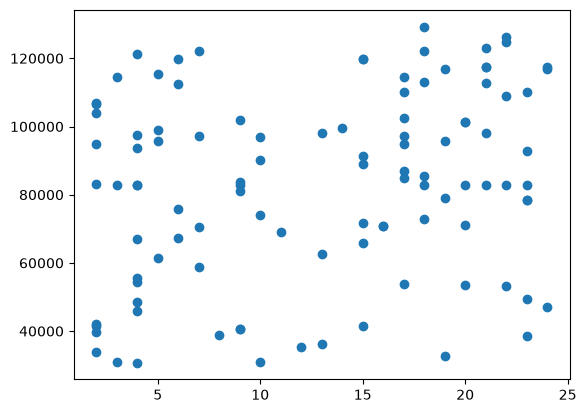

In [221]:
import matplotlib.pyplot as plt
plt.scatter(df['Experience'],df['Salary'])

Step4:statistical analysis

Department wise mean salary
Department
Finance       78723.450000
HR            89057.729167
IT            80443.510417
Marketing     80534.131510
Operations    75343.332031
Sales         89162.050189
Name: Salary, dtype: float64
Department wise highest salary
Department  Performance
Finance     Average        106820.0
            Excellent      115305.0
            Good           122093.0
HR          Average        129299.0
            Excellent      124663.0
            Good           126276.0
IT          Average         94925.0
            Excellent       97221.0
            Good           122067.0
Marketing   Average         53247.0
            Excellent      113104.0
            Good           119812.0
Operations  Average        104065.0
            Excellent       97435.0
            Good           110077.0
Sales       Average        123016.0
            Excellent      116779.0
            Good            86886.0
Name: Salary, dtype: float64


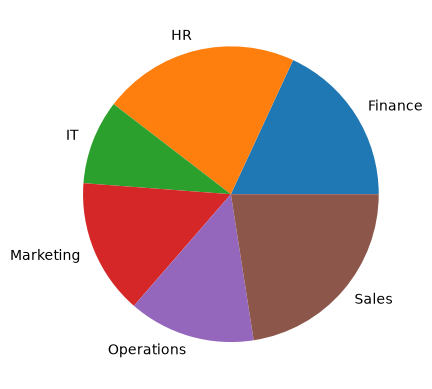

In [222]:
df1=df.groupby(['Department'])['Salary'].sum()
df1.plot(kind='pie')
print('Department wise mean salary')
print(df.groupby(['Department'])['Salary'].mean())

#department wise highest salary
print('===============================')
print('Department wise highest salary')
print(df.groupby(['Department',"Performance"])['Salary'].max())



In [223]:
# df['Department_mean_sal']= df.groupby(['Department'])['Salary'].transform('mean')
# df.insert(5,'Department_mean_salalary',df.groupby(['Department'])['Salary'].transform('mean'))
# df.drop(columns='Department_mean_sal')

Step5:Outlier removal

In [224]:
Q1= df['Salary'].quantile(.25)
Q3= df['Salary'].quantile(.75)
IQR = Q3-Q1

lower_bound = Q1-1.5*IQR

upper_bound = Q3+1.5*IQR

np.clip(df['Salary'],lower_bound,upper_bound)

0       82902.104167
1       30860.000000
2      106820.000000
3       84886.000000
4       36265.000000
           ...      
100    119812.000000
101     78555.000000
102    101211.000000
103     40627.000000
104    117313.000000
Name: Salary, Length: 105, dtype: float64

Step6:df[features].to_numpy(dtype=np.float32)` → ML feature matrix 

Step7:Export to csv

In [225]:
#export to csv
df.to_csv('ABC_Company.csv')

import csv

In [226]:
df2= pd.read_csv(r'D:\NumPy\ABC_Company.csv')
df2.sample(5)

,Unnamed: 0,Emp_ID,Names,Age,Department,Salary,Rating,Experience,Performance,Remark
72,72,173,Preeti,36.000000,IT,67065.0,9,4,Excellent,Higher Salary
70,70,171,Tanvi,34.000000,Operations,101211.0,6,20,Good,Higher Experience
92,92,193,Chirag,37.179775,Sales,116779.0,9,19,Excellent,Higher Salary
55,55,156,Nisha,36.000000,Operations,110077.0,6,23,Good,Higher Experience
5,5,106,Sai,23.000000,HR,112386.0,8,6,Good,Higher Salary


## 🎯 Quick Hints Reference

| Task | NumPy Function | Pandas Equivalent |
|------|---------------|-------------------|
| Convert to array | `arr = df["col"].values` | `arr = df["col"].to_numpy()` |
| Conditional assign | `np.where(cond, a, b)` | `df.loc[cond, "col"] = val` |
| Multi-condition | `np.select([c1,c2],[v1,v2])` | `map()` / `pd.cut()` |
| Clip values | `np.clip(arr, lo, hi)` | `df["col"].clip(lo, hi)` |
| Count NaN | `np.isnan(arr).sum()` | `df.isnull().sum()` |
| Correlation | `np.corrcoef([a, b])` | `df.corr()` |
| Percentile | `np.percentile(arr, q)` | `df["col"].quantile(q/100)` |
| Cumulative sum | `np.cumsum(arr)` | `df["col"].cumsum()` |
| Sort indices | `np.argsort(arr)` | `df.sort_values(...).index` |
| Unique values | `np.unique(arr)` | `df["col"].unique()` |
| Reshape | `arr.reshape(r, c)` | — (use before DataFrame creation) |
| Min-Max scale | `(x - x.min()) / (x.max()-x.min())` | Manual or sklearn |
| Z-score | `(x - x.mean()) / x.std()` | Manual or sklearn |

---

*📌 Always try solving without hints first.*  
*⭐ Happy Learning NumPy + Pandas — the backbone of every ML project!*